# $Z'$ observed exclusions 

**Inputs:** (1) the rescaled SLHA folder, (2) the corresponding SModelS Python output folder. 

**Workflow:** Read SLHAs → read all SModelS `ExptRes` entries → reconstruct $\sigma_{95}^{\mathrm{obs}}=\sigma_{\mathrm{channel}}/r$ → check consistency across SLHAs at fixed mass → draw the three experimental curves. The top-dominant and jet-dominant SLHAs contribute to **the same experimental limits**.




In [29]:
from pathlib import Path
import importlib.util
import re
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


slha_dir = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_0p99w_SLHAs')
smodels_dir = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_0p99w_SModelS_out')
output_dir = Path('./')

width_fraction = 0.0099
k_factor = 1.0
min_r = 1e-8
max_relative_spread = 0.05
mass_step = 100
mass_range = (1500, 5000)
cross_section_range = (1e-6, 1e-1)
show_scan_envelopes = False
show_plots = True
save_limit_table = False  

benchmark_slha = None
colors = plt.cm.tab20.colors

analyses={
 'CMS-EXO-19-012':dict(channel='dijet',title='CMS dijet',color=colors[8],label='CMS-EXO-19-012 (dijet)', ls = '-'),
 'ATLAS-EXOT-2019-03':dict(channel='dijet',title='ATLAS dijet',color=colors[6],label='ATLAS-EXOT-2019-03 (dijet)', ls = '-'),
 'ATLAS-EXOT-2018-48':dict(channel=r'$t\bar{t}$',title=r'ATLAS $t\bar t$',color=colors[2],label=r'ATLAS-EXOT-2018-48 ($t\bar t$)', ls = '-'),
}


benchmark={
 'mass_GeV':3000.0,
 'sigma_tt_pb':1.048e-3,
 'sigma_jj_pb': (2.0523540e-04/9.978330e-01*2*1.083506e-03
                 +8.4286538e-04/9.978330e-01*2*1.083506e-03),
}
plt.rcParams.update({'savefig.dpi':300})

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)

##  Read the theoretical information directly from each SLHA


In [30]:
def number(value):
    return float(value.replace('D', 'E').replace('d', 'e'))


def read_slha(path):
    block = None
    decay_pdg = None
    in_xsection = False
    masses, widths, cross_sections = [], [], []
    branching = {}
    couplings = {}

    for line in path.read_text().splitlines():
        words = line.partition('#')[0].split()
        if not words:
            continue
        tag = words[0].upper()
        if tag == 'BLOCK':
            block = words[1].upper()
            decay_pdg = None
            in_xsection = False
            continue
        if tag == 'DECAY':
            block = None
            in_xsection = False
            decay_pdg = int(words[1])
            if decay_pdg == 5000001:
                widths.append(number(words[2]))
            continue
        if tag == 'XSECTION':
            block = None
            decay_pdg = None
            in_xsection = (len(words) >= 6 and abs(number(words[1]) - 13000) < 1
                           and tuple(map(int, words[2:6])) == (2212, 2212, 1, 5000001))
            continue
        if block == 'MASS' and words[0] == '5000001':
            masses.append(number(words[1]))
        elif block == 'DMINPUTS' and words[0] in ('4', '5', '9'):
            couplings[int(words[0])] = number(words[1])
        elif decay_pdg == 5000001 and len(words) >= 4 and words[1] == '2':
            channel = tuple(sorted((int(words[2]), int(words[3]))))
            branching[channel] = number(words[0])
        elif in_xsection and len(words) >= 7:
            try:
                tuple(int(value) for value in words[:6])
                cross_sections.append((number(words[6]), 'ufo2slha' in line.lower()))
            except ValueError:
                continue

    preferred = [value for value, generated in cross_sections if generated]
    candidates = preferred or [value for value, generated in cross_sections]
    if len(masses) != 1 or len(widths) != 1 or len(candidates) != 1:
        raise ValueError(f'{path}: ambiguous mass, width or 13 TeV pp -> Zprime XSECTION')
    if not {(-6, 6), (-2, 2), (-1, 1)}.issubset(branching):
        raise ValueError(f'{path}: missing Zprime -> tt/uubar/ddbar branching ratios')
    if set(couplings) != {4, 5, 9}:
        raise ValueError(f'{path}: missing DMINPUTS entries 4, 5 or 9')
    if not np.isclose(sum(branching.values()), 1.0, atol=3e-5):
        raise ValueError(f'{path}: branching ratios do not sum to 1')

    mass = masses[0]
    production = candidates[0]
    br_tt = branching[(-6, 6)]
    br_jj = sum(value for channel, value in branching.items()
                if abs(channel[0]) in (1, 2, 3, 4, 5))
    return dict(filename=path.name, mass_gev=mass, width_fraction=widths[0]/mass,
                gq=couplings[4], gt=couplings[9],
                regime='topDom' if couplings[9] > couplings[4] else 'jetDom',
                sigma_prod_pb=production, sigma_tt_pb=production*br_tt,
                sigma_jj_pb=production*br_jj, br_tt=br_tt, br_jj=br_jj)


slha_paths = sorted(slha_dir.glob('*.slha'))
if not slha_paths:
    raise FileNotFoundError(f'No .slha files in {slha_dir}')
points = pd.DataFrame([read_slha(path) for path in slha_paths])
if points.filename.duplicated().any():
    raise ValueError('Duplicate SLHA filenames')
if not np.allclose(points.width_fraction, width_fraction, rtol=0, atol=5e-8):
    raise ValueError('The SLHA folder contains files that are not at 0.99% width')
print(f'{len(points):,} SLHAs across {points.mass_gev.nunique()} masses')
display(points.groupby('regime').size().rename('points').reset_index())


5,246 SLHAs across 43 masses


,regime,points
0,jetDom,2279
1,topDom,2967


## Read the SModelS outputs directly


In [31]:
def read_smodels(path):
    name = 'smodels_result_' + re.sub(r'\W', '_', path.stem)
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.smodelsOutput


output_paths = sorted(smodels_dir.glob('*.py'))
if not output_paths:
    raise FileNotFoundError(f'No SModelS .py outputs in {smodels_dir}')
known_files = set(points.filename)
reported_rows = []
processed_files = set()
for path in output_paths:
    result = read_smodels(path)
    input_file = result.get('OutputStatus', {}).get('input file')
    if not input_file:
        raise ValueError(f'Missing OutputStatus input file in {path}')
    filename = Path(input_file).name
    if Path(filename).suffix.lower() != '.slha':
        print(f'Skipping non-SLHA input: {filename}')
        continue
    if filename not in known_files:
        raise ValueError(f'SModelS output references an unknown SLHA: {filename}')
    if filename in processed_files:
        raise ValueError(f'Multiple SModelS outputs for one SLHA: {filename}')
    processed_files.add(filename)
    results = result.get('ExptRes', []) or []
    if isinstance(results, dict):
        results = list(results.values())
    for entry in results:
        analysis = str(entry.get('AnalysisID', '')).strip()
        if analysis not in analyses:
            continue
        reported_rows.append(dict(filename=filename, analysis=analysis,
                                  r_reported=pd.to_numeric(entry.get('r'), errors='coerce')))

missing_outputs = known_files - processed_files
if missing_outputs:
    print(f'WARNING: {len(missing_outputs)} SLHAs lack SModelS outputs, examples: {sorted(missing_outputs)[:5]}')
reported = pd.DataFrame(reported_rows, columns=['filename', 'analysis', 'r_reported'])
if reported.empty:
    raise ValueError('None of the three requested analyses occurs in these SModelS results')

duplicated = reported.duplicated(['filename', 'analysis'], keep=False)
if duplicated.any():
    repeats = reported.loc[duplicated, ['filename', 'analysis']].drop_duplicates()
    raise ValueError(f'Duplicate results for the same analysis and SLHA; inspect datasets:\n{repeats.head(10)}')
reported = reported.merge(points, on='filename', how='left', validate='many_to_one')
reported['sigma_channel_pb'] = np.where(reported.analysis.eq('ATLAS-EXOT-2018-48'),
                                        reported.sigma_tt_pb, reported.sigma_jj_pb)
reported['ul_pb_from_r'] = (
    reported.sigma_channel_pb / reported.r_reported
)
reported['valid'] = (np.isfinite(reported.r_reported) & (reported.r_reported >= min_r)
                     & np.isfinite(reported.ul_pb_from_r) & (reported.ul_pb_from_r > 0))
print(f'Read {len(processed_files):,} SModelS outputs; {int(reported.valid.sum()):,} valid analysis ratios')
display(reported.groupby(['analysis', 'valid']).size().rename('rows').reset_index())


Read 5,246 SModelS outputs; 8,636 valid analysis ratios


,analysis,valid,rows
0,ATLAS-EXOT-2018-48,True,3498
1,ATLAS-EXOT-2019-03,True,2032
2,CMS-EXO-19-012,True,3106


## Reconstruct the upper limits and check consistency


In [32]:
valid_rows = reported.loc[reported.valid].copy()
limits = (valid_rows.groupby(['analysis', 'mass_gev'], as_index=False)
          .agg(ul_pb=('ul_pb_from_r', 'median'),
               ul_min_pb=('ul_pb_from_r', 'min'),
               ul_max_pb=('ul_pb_from_r', 'max'),
               n_reported=('filename', 'size')))
limits['relative_spread'] = (limits.ul_max_pb - limits.ul_min_pb) / limits.ul_pb
limits['status'] = np.where(limits.relative_spread <= max_relative_spread,
                            'reconstructed', 'inconsistent')
limits.loc[limits.status.ne('reconstructed'), 'ul_pb'] = np.nan

complete_index = pd.MultiIndex.from_product(
    [list(analyses), sorted(points.mass_gev.unique())], names=['analysis', 'mass_gev'])
limits = limits.set_index(['analysis', 'mass_gev']).reindex(complete_index).reset_index()
limits['status'] = limits.status.fillna('not reported')
limits['n_reported'] = limits.n_reported.fillna(0).astype(int)
print('Upper-limit coverage by analysis:')
display(limits.groupby(['analysis', 'status']).size().rename('mass points').reset_index())


analysis_columns = {
    'CMS-EXO-19-012': ('cms_jj', 'sigma_jj_pb'),
    'ATLAS-EXOT-2019-03': ('atlas_jj', 'sigma_jj_pb'),
    'ATLAS-EXOT-2018-48': ('atlas_tt', 'sigma_tt_pb'),
}

for analysis, (name, signal) in analysis_columns.items():

    # Experimental upper limit for each mass
    upper_limits = (
        limits.loc[limits.analysis.eq(analysis)]
        .set_index('mass_gev')['ul_pb']
    )

    # Assign the same experimental limit to all SLHAs at a given mass
    points[f'ul_{name}'] = points.mass_gev.map(upper_limits)

    ul = points[f'ul_{name}']
    valid = np.isfinite(ul) & (ul > 0) & np.isfinite(points[signal]) & (points[signal] > 0)

    # Reconstruct the ratio using the experimental limit
    points[f'r_{name}'] = np.nan
    points.loc[valid, f'r_{name}'] = (
        k_factor * points.loc[valid, signal] / ul.loc[valid]
    )

# Combined classification
ratio_columns = ['r_cms_jj', 'r_atlas_jj', 'r_atlas_tt']

points['n_limits'] = points[ratio_columns].notna().sum(axis=1)
points['r_max'] = points[ratio_columns].max(axis=1)

points['status'] = np.select(
    [
        points.r_max.gt(1),
        points.n_limits.eq(len(analysis_columns)),
        points.n_limits.eq(0)
    ],
    [
        'excluded',
        'not excluded by all three',
        'no usable limits'
    ],
    default='not excluded by available limits (partial coverage)'
)

# Verify the results
print("Points per classification:")
print(points['status'].value_counts())

print("\nValid limits for each analysis:")
print(points[ratio_columns].notna().sum())
display(points.status.value_counts().rename_axis('classification').reset_index(name='points'))


Upper-limit coverage by analysis:


,analysis,status,mass points
0,ATLAS-EXOT-2018-48,not reported,10
1,ATLAS-EXOT-2018-48,reconstructed,33
2,ATLAS-EXOT-2019-03,not reported,22
3,ATLAS-EXOT-2019-03,reconstructed,21
4,CMS-EXO-19-012,not reported,10
5,CMS-EXO-19-012,reconstructed,33


Points per classification:
status
not excluded by available limits (partial coverage)    1959
excluded                                               1667
no usable limits                                        854
not excluded by all three                               766
Name: count, dtype: int64

Valid limits for each analysis:
r_cms_jj      4026
r_atlas_jj    2562
r_atlas_tt    4026
dtype: int64


,classification,points
0,not excluded by available limits (partial cove...,1959
1,excluded,1667
2,no usable limits,854
3,not excluded by all three,766


## Scan points and individual upper limits



CMS-EXO-19-012: 970 excluded points, 3056 not excluded, 1220 without reconstructed limits
ATLAS-EXOT-2019-03: 1418 excluded points, 1144 not excluded, 2684 without reconstructed limits
ATLAS-EXOT-2018-48: 671 excluded points, 3355 not excluded, 1220 without reconstructed limits


/tmp/ipykernel_72871/3831847456.py:39: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(subset.mass_gev, subset[signal], s=9, c=color,
/tmp/ipykernel_72871/3831847456.py:39: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(subset.mass_gev, subset[signal], s=9, c=color,
/tmp/ipykernel_72871/3831847456.py:39: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as 

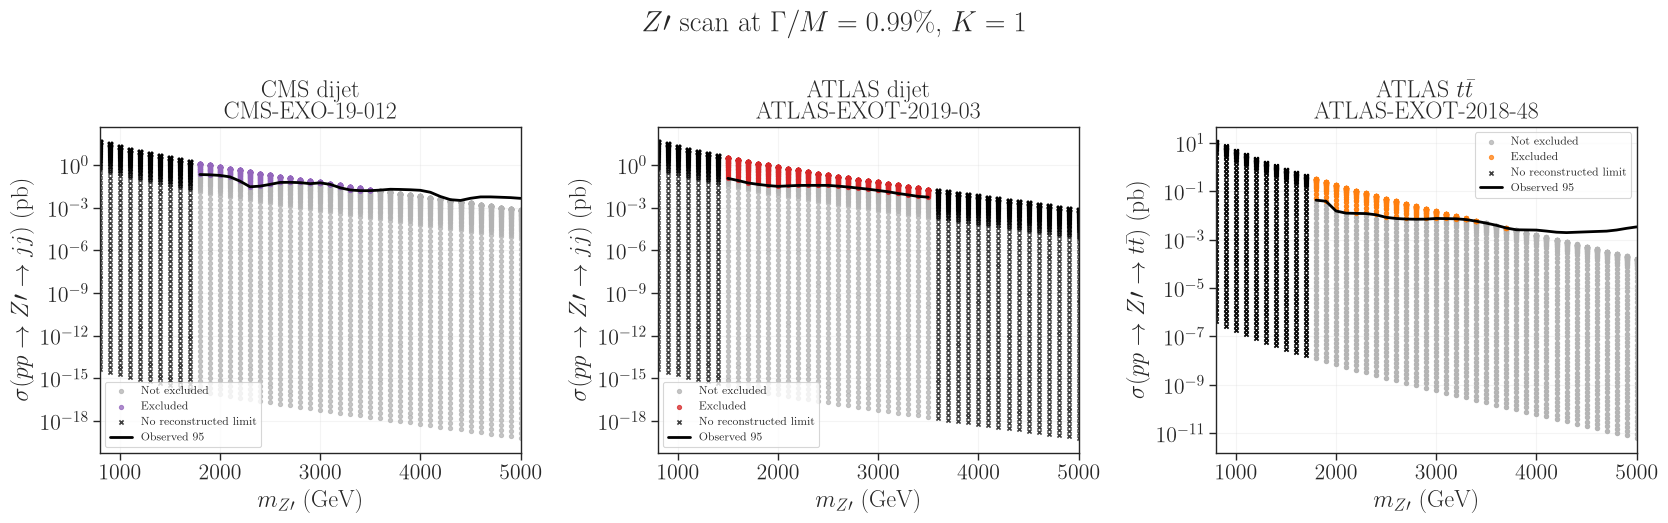

Saved individual_exclusions.png


In [33]:
def line_segments(frame):
    valid = frame.loc[np.isfinite(frame.ul_pb) & frame.ul_pb.gt(0)].sort_values('mass_gev')
    if valid.empty:
        return []
    values = valid.mass_gev.to_numpy()
    breaks = np.r_[0, np.flatnonzero(np.diff(values) > mass_step * 1.01) + 1, len(values)]
    return [valid.iloc[breaks[index]:breaks[index + 1]] for index in range(len(breaks) - 1)]


def diagnostic_plot():
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), sharex=True)
    for ax, (analysis, config) in zip(axes, analyses.items()):
        short_name, signal = analysis_columns[analysis]
        limit_table = limits.loc[limits.analysis.eq(analysis), ['mass_gev', 'ul_pb']]
        scan = points[['filename', 'mass_gev', signal]].merge(
            limit_table, on='mass_gev', how='left', validate='many_to_one'
        )
        valid_signal = np.isfinite(scan[signal]) & scan[signal].gt(0)
        valid_limit = np.isfinite(scan.ul_pb) & scan.ul_pb.gt(0)
        ratio = np.where(valid_signal & valid_limit,
                         k_factor * scan[signal] / scan.ul_pb, np.nan)
        excluded = valid_signal & valid_limit & (ratio > 1)
        not_excluded = valid_signal & valid_limit & (ratio <= 1)
        no_limit = valid_signal & ~valid_limit

        # Exclusion status and the y-coordinate MUST use the same cross section.
        if np.any(excluded & ~(k_factor * scan[signal] > scan.ul_pb)):
            raise AssertionError(f'Excluded scan point below observed limit for {analysis}')
        if np.any(not_excluded & ~(k_factor * scan[signal] <= scan.ul_pb)):
            raise AssertionError(f'Allowed scan point above observed limit for {analysis}')

        for mask, color, label, marker in [
            (not_excluded, '0.70', 'Not excluded', 'o'),
            (excluded, config['color'], 'Excluded', 'o'),
            (no_limit, 'black', 'No reconstructed limit', 'x'),
        ]:
            subset = scan.loc[mask]
            if not subset.empty:
                ax.scatter(subset.mass_gev, subset[signal], s=9, c=color,
                           marker=marker, rasterized=True, label=label, alpha=0.75)

        for index, segment in enumerate(line_segments(limits.loc[limits.analysis.eq(analysis)])):
            ax.plot(segment.mass_gev, segment.ul_pb, c='black', lw=2,
                    label='Observed 95% CL' if index == 0 else None)

        print(f'{analysis}: {int(excluded.sum())} excluded points, '
              f'{int(not_excluded.sum())} not excluded, '
              f'{int(no_limit.sum())} without reconstructed limits')
        ax.set_yscale('log')
        ax.set_xlim(800, 5000)
        ax.set_xlabel(r'$m_{Z\prime}$ (GeV)')
        final_state = r't\bar t' if signal == 'sigma_tt_pb' else 'jj'
        ax.set_ylabel(r'$\sigma(pp\to Z\prime\to '+final_state+r')$ (pb)')
        ax.set_title(config['title'] + '\n' + analysis)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(r'$Z\prime$ scan at $\Gamma/M=0.99\%$, $K=1$')
    fig.tight_layout()
    path = output_dir / 'individual_exclusions.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    if show_plots:
        plt.show()
    else:
        plt.close(fig)
    print('Saved', path)


diagnostic_plot()


## Experimental exclusion curves


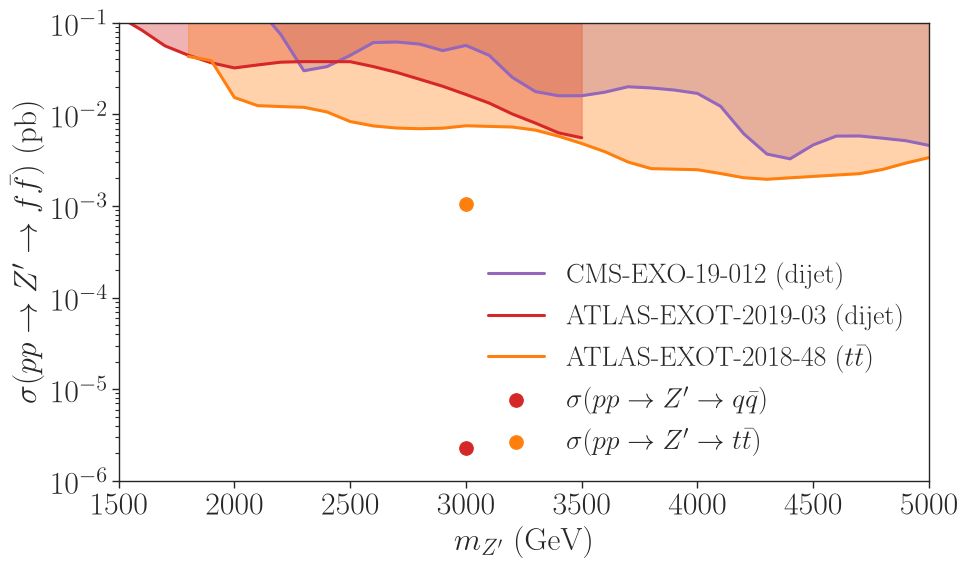

In [34]:
def final_plot():
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_yscale('log')
    ax.set_xlim(*mass_range)
    ax.set_ylim(*cross_section_range)
    ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)',fontsize=23)
    ax.set_ylabel(r'$\sigma(pp\to Z^\prime\to f\bar f)$ (pb)',fontsize=23)
    ax.tick_params(labelsize=23)

    for analysis, config in analyses.items():
        sections = line_segments(limits.loc[limits.analysis.eq(analysis)])
        for index, segment in enumerate(sections):
            ax.plot(segment.mass_gev, segment.ul_pb, lw=2.2,
                    color=config['color'], ls = config['ls'], label=f'{analysis} ({config["channel"]})' if index == 0 else None)
            ax.fill_between(segment.mass_gev, segment.ul_pb, cross_section_range[1],
                            color=config['color'], alpha=0.35)
    if show_scan_envelopes:
        envelope = (points.groupby('mass_gev', as_index=False)
                    .agg(max_jj_pb=('sigma_jj_pb', 'max'), max_tt_pb=('sigma_tt_pb', 'max'))
                    .sort_values('mass_gev'))
        ax.plot(envelope.mass_gev, envelope.max_jj_pb, '--', c='firebrick', alpha=0.65,
                lw=1.4, label='Maximum scanned dijet signal')
        ax.plot(envelope.mass_gev, envelope.max_tt_pb, '--', c='mediumorchid', alpha=0.65,
                lw=1.4, label=r'Maximum scanned $t\bar t$ signal')
        
    ax.scatter([benchmark['mass_GeV']],[benchmark['sigma_jj_pb']],s=95,marker='o',
                                   color=analyses['ATLAS-EXOT-2019-03']['color'],zorder=5,
                                   label=r'$\sigma(pp\to Z^\prime\to q\bar q)$')
    ax.scatter([benchmark['mass_GeV']],[benchmark['sigma_tt_pb']],s=95,marker='o',
                                   color=analyses['ATLAS-EXOT-2018-48']['color'],zorder=5,
                                   label=r'$\sigma(pp\to Z^\prime\to t\bar t)$')
    ax.legend(loc='lower right', framealpha=0, fontsize=20)
    fig.tight_layout()
    path = './observed_exclusion_curves.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()
    


final_plot()
if save_limit_table:
    limits.to_csv('./observed_limits.csv', index=False)
    print('Saved optional observed_limits.csv')


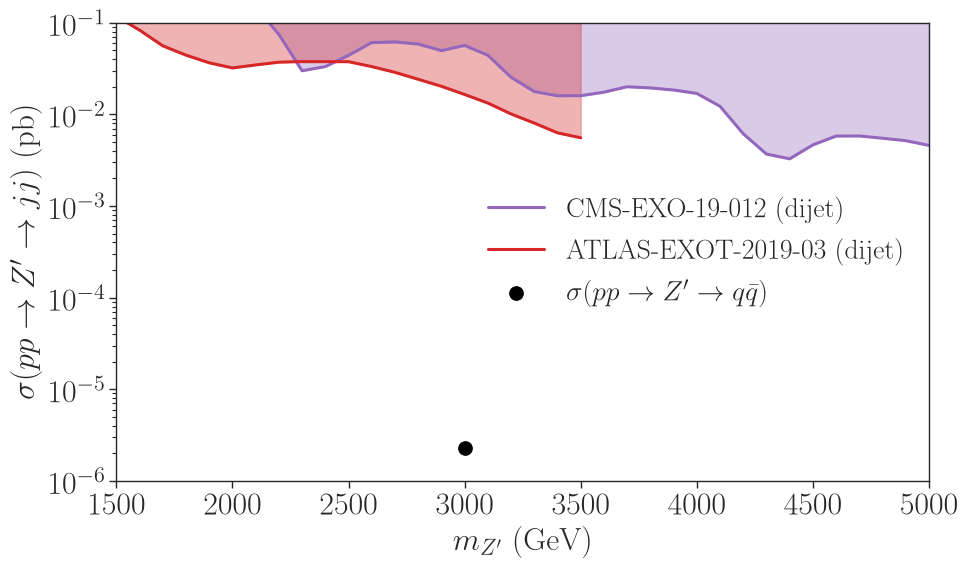

Saved ../paper_plots/directSearches_Zprime_qq.png


In [48]:
# Dijet-only observed exclusion curves and dijet benchmark
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_yscale('log')
ax.set_xlim(*mass_range)
ax.set_ylim(*cross_section_range)
ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\sigma(pp\to Z^\prime\to jj)$ (pb)', fontsize=23)
ax.tick_params(labelsize=23)

for analysis in ['CMS-EXO-19-012', 'ATLAS-EXOT-2019-03']:
    config = analyses[analysis]
    sections = line_segments(limits.loc[limits.analysis.eq(analysis)])
    for index, segment in enumerate(sections):
        ax.plot(segment.mass_gev, segment.ul_pb, lw=2.2,
                color=config['color'], ls=config['ls'],
                label=f'{analysis} ({config["channel"]})' if index == 0 else None)
        ax.fill_between(segment.mass_gev, segment.ul_pb, cross_section_range[1],
                        color=config['color'], alpha=0.35)

if show_scan_envelopes:
    envelope = (points.groupby('mass_gev', as_index=False)
                .agg(max_jj_pb=('sigma_jj_pb', 'max')).sort_values('mass_gev'))
    ax.plot(envelope.mass_gev, envelope.max_jj_pb, '--',
            c='firebrick', alpha=0.65, lw=1.4,
            label='Maximum scanned dijet signal')

ax.scatter([benchmark['mass_GeV']], [benchmark['sigma_jj_pb']],
           s=95, marker='o', color='black',
           zorder=5, label=r'$\sigma(pp\to Z^\prime\to q\bar q)$')
ax.legend(loc='center right', framealpha=0, fontsize=20)
fig.tight_layout()
path = '../paper_plots/directSearches_Zprime_qq.png'
fig.savefig(path, dpi=300, bbox_inches='tight')
if show_plots:
    plt.show()
else:
    plt.close(fig)
print('Saved', path)


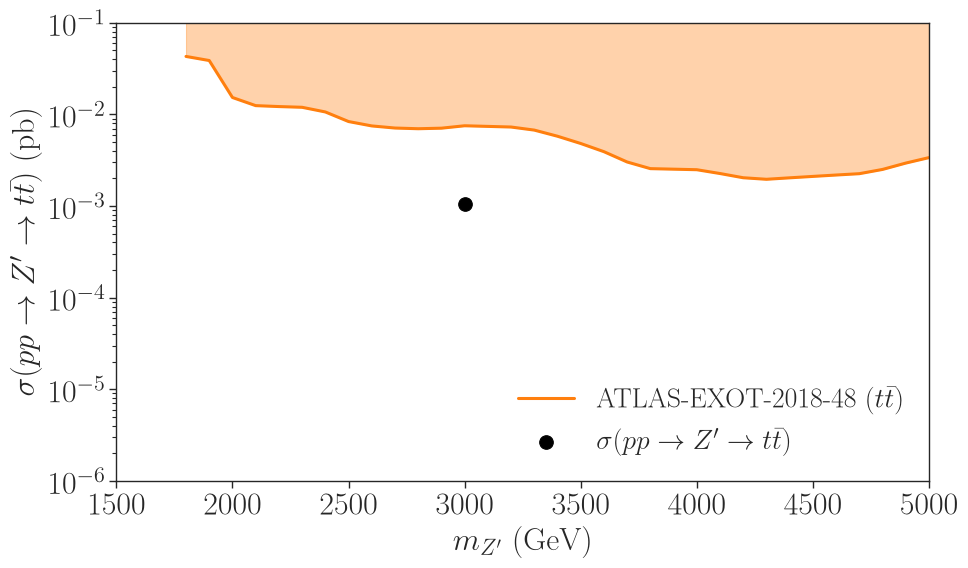

Saved ../paper_plots/directSearches_Zprime_tt.png


In [44]:
# Top-pair-only observed exclusion curve and ttbar benchmark
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_yscale('log')
ax.set_xlim(*mass_range)
ax.set_ylim(*cross_section_range)
ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\sigma(pp\to Z^\prime\to t\bar t)$ (pb)', fontsize=23)
ax.tick_params(labelsize=23)

analysis = 'ATLAS-EXOT-2018-48'
config = analyses[analysis]
sections = line_segments(limits.loc[limits.analysis.eq(analysis)])
for index, segment in enumerate(sections):
    ax.plot(segment.mass_gev, segment.ul_pb, lw=2.2,
            color=config['color'], ls=config['ls'],
            label=f'{analysis} ({config["channel"]})' if index == 0 else None)
    ax.fill_between(segment.mass_gev, segment.ul_pb, cross_section_range[1],
                    color=config['color'], alpha=0.35)

if show_scan_envelopes:
    envelope = (points.groupby('mass_gev', as_index=False)
                .agg(max_tt_pb=('sigma_tt_pb', 'max')).sort_values('mass_gev'))
    ax.plot(envelope.mass_gev, envelope.max_tt_pb, '--',
            c='mediumorchid', alpha=0.65, lw=1.4,
            label=r'Maximum scanned $t\bar t$ signal')

ax.scatter([benchmark['mass_GeV']], [benchmark['sigma_tt_pb']],
           s=95, marker='o', color='black', zorder=5,
           label=r'$\sigma(pp\to Z^\prime\to t\bar t)$')
ax.legend(loc='lower right', framealpha=0, fontsize=20)
ax.set_xlim(1500,5000)
fig.tight_layout()
path = '../paper_plots/directSearches_Zprime_tt.png'
fig.savefig(path, dpi=300, bbox_inches='tight')
if show_plots:
    plt.show()
else:
    plt.close(fig)
print('Saved', path)
